In [ ]:
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize


# ============================================================
# 0. Basic settings
# ============================================================

ROOT = Path(r"C:\Users\heyuxuan\Desktop\Inversion_results")

# ------------------------------------------------------------
# True / initial model folders
# ------------------------------------------------------------

TRUE_DIR_CANDIDATES = [
    ROOT / "Model",
    ROOT / "Models",
    ROOT / "True",
    ROOT / "True_model",
    ROOT / "True_models",
    ROOT / "Model_new",
]

# Three inversion results
RUNS = {
    "L2":  ROOT / "Initial_10hz_smooth" / "Intermediate",
    "COT": ROOT / "Initial_10hz_ot_sp_5_smooth" / "Intermediate",
    "ROT": ROOT / "Initial_10hz_ot_revised_corrected_4e-4_sp_5_smooth" / "Intermediate",
}

# Initial model.
# Usually this is exactly the starting model saved by the inversion.
INIT_DIR = RUNS["L2"] / "iter_0000_initial"

# Grid spacing, unit: m
dx = 10.0
dz = 10.0
dx_km = dx / 1000.0
dz_km = dz / 1000.0

CMAP = "jet"

SAVE_DIR = ROOT / "save_linear"
SAVE_DIR.mkdir(exist_ok=True)

# LaTeX-friendly PDF settings
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.size"] = 11


# ============================================================
# 1. Utilities
# ============================================================

def check_path(path, description="path"):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{description} does not exist:\n{path}")


def find_true_dir(candidates):
    for folder in candidates:
        if (folder / "vp.npy").exists() and (folder / "vs.npy").exists():
            return folder

    msg = "Cannot find true model folder automatically.\n"
    msg += "Please set TRUE_DIR manually. Tried:\n"
    for folder in candidates:
        msg += f"  {folder}\n"
    raise FileNotFoundError(msg)


def load_vp_vs(folder):
    folder = Path(folder)
    check_path(folder / "vp.npy", "vp.npy")
    check_path(folder / "vs.npy", "vs.npy")
    vp = np.load(folder / "vp.npy")
    vs = np.load(folder / "vs.npy")
    return vp, vs


def get_extent(A):
    """
    A shape is assumed to be (nx, nz).

    We plot A.T with origin='upper'. The extent below gives:
        x: distance, left to right
        z: depth, top to bottom
    """
    nx, nz = A.shape
    lx = nx * dx_km
    lz = nz * dz_km
    return [0.0, lx, lz, 0.0]


def save_fig(fig, name, dpi=600):
    png_path = SAVE_DIR / f"{name}.png"
    pdf_path = SAVE_DIR / f"{name}.pdf"

    fig.savefig(png_path, dpi=dpi, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(pdf_path, bbox_inches="tight", pad_inches=0.02)

    plt.close(fig)

    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")


def save_model_image(A, name, norm, cbar_label, dpi=600):
    """
    Save a single 2D model image.

    No title is added, so the figure is clean for LaTeX subfigure captions.
    """
    nx, nz = A.shape

    fig_width = 5.0
    fig_height = fig_width * (nz * dz_km) / (nx * dx_km)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    im = ax.imshow(
        A.T,
        cmap=CMAP,
        norm=norm,
        origin="upper",
        extent=get_extent(A),
        aspect="equal",
    )

    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Depth (km)")

    cbar = fig.colorbar(im, ax=ax, shrink=0.95)
    cbar.set_label(cbar_label)

    save_fig(fig, name, dpi=dpi)


def save_center_profile(component, x_mid, depth, profile_models, name, dpi=600):
    """
    Save center depth profile.

    Horizontal axis: depth.
    Vertical axis: velocity.
    """
    fig, ax = plt.subplots(figsize=(5.2, 4.0))

    for label, model in profile_models.items():
        ax.plot(depth, model[component][x_mid, :], label=label)

    ax.set_xlabel("Depth (km)")

    if component == "vp":
        ax.set_ylabel(r"$v_p$ (km/s)")
    elif component == "vs":
        ax.set_ylabel(r"$v_s$ (km/s)")
    else:
        ax.set_ylabel(component)

    ax.grid(True, linestyle=":")
    ax.legend(frameon=False)

    save_fig(fig, name, dpi=dpi)


# ============================================================
# 2. Load models
# ============================================================

TRUE_DIR = find_true_dir(TRUE_DIR_CANDIDATES)

for name, path in RUNS.items():
    check_path(path, f"{name} run directory")
    check_path(path / "final", f"{name} final directory")

check_path(INIT_DIR, "initial model directory")

vp_true, vs_true = load_vp_vs(TRUE_DIR)
vp_init, vs_init = load_vp_vs(INIT_DIR)

final_models = {}
for name, run_dir in RUNS.items():
    vp, vs = load_vp_vs(run_dir / "final")
    final_models[name] = {"vp": vp, "vs": vs}


# Basic shape checks
model_shape = vp_true.shape
for label, A in [
    ("vs_true", vs_true),
    ("vp_init", vp_init),
    ("vs_init", vs_init),
    ("L2 vp", final_models["L2"]["vp"]),
    ("L2 vs", final_models["L2"]["vs"]),
    ("COT vp", final_models["COT"]["vp"]),
    ("COT vs", final_models["COT"]["vs"]),
    ("ROT vp", final_models["ROT"]["vp"]),
    ("ROT vs", final_models["ROT"]["vs"]),
]:
    if A.shape != model_shape:
        raise ValueError(
            f"Shape mismatch: {label} has shape {A.shape}, "
            f"but true vp has shape {model_shape}."
        )

nx, nz = model_shape

print(f"True model directory: {TRUE_DIR}")
print(f"Initial model directory: {INIT_DIR}")
print(f"Model shape: {model_shape}")
print(f"Domain size: {nx * dx_km:.2f} km × {nz * dz_km:.2f} km")


# ============================================================
# 3. Shared color limits
# ============================================================

all_vp = [
    vp_true,
    vp_init,
    final_models["L2"]["vp"],
    final_models["COT"]["vp"],
    final_models["ROT"]["vp"],
]

all_vs = [
    vs_true,
    vs_init,
    final_models["L2"]["vs"],
    final_models["COT"]["vs"],
    final_models["ROT"]["vs"],
]

vp_norm = Normalize(
    vmin=min(np.min(A) for A in all_vp),
    vmax=max(np.max(A) for A in all_vp),
)

vs_norm = Normalize(
    vmin=min(np.min(A) for A in all_vs),
    vmax=max(np.max(A) for A in all_vs),
)


# ============================================================
# 4. Save true and initial model images
# ============================================================

save_model_image(vp_true, "true_vp", vp_norm, r"$v_p$ (km/s)")
save_model_image(vs_true, "true_vs", vs_norm, r"$v_s$ (km/s)")

save_model_image(vp_init, "initial_vp", vp_norm, r"$v_p$ (km/s)")
save_model_image(vs_init, "initial_vs", vs_norm, r"$v_s$ (km/s)")


# ============================================================
# 5. Save final inversion model images
# ============================================================

save_model_image(final_models["L2"]["vp"], "l2_vp", vp_norm, r"$v_p$ (km/s)")
save_model_image(final_models["L2"]["vs"], "l2_vs", vs_norm, r"$v_s$ (km/s)")

save_model_image(final_models["COT"]["vp"], "cot_vp", vp_norm, r"$v_p$ (km/s)")
save_model_image(final_models["COT"]["vs"], "cot_vs", vs_norm, r"$v_s$ (km/s)")

save_model_image(final_models["ROT"]["vp"], "rot_vp", vp_norm, r"$v_p$ (km/s)")
save_model_image(final_models["ROT"]["vs"], "rot_vs", vs_norm, r"$v_s$ (km/s)")


# ============================================================
# 6. Save center depth profiles
# ============================================================

x_mid = nx // 2
depth = np.arange(nz) * dz_km

profile_models = {
    "True": {"vp": vp_true, "vs": vs_true},
    "Initial": {"vp": vp_init, "vs": vs_init},
    "L2": final_models["L2"],
    "COT": final_models["COT"],
    "ROT": final_models["ROT"],
}

save_center_profile("vp", x_mid, depth, profile_models, "center_profile_vp")
save_center_profile("vs", x_mid, depth, profile_models, "center_profile_vs")


print(f"\nAll figures have been saved to:\n{SAVE_DIR}")

True model directory: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\Model
Initial model directory: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\Initial_10hz_smooth\Intermediate\iter_0000_initial
Model shape: (500, 174)
Domain size: 5.00 km × 1.74 km
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\true_vp.png
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\true_vp.pdf
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\true_vs.png
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\true_vs.pdf
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\initial_vp.png
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\initial_vp.pdf
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\initial_vs.png
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\initial_vs.pdf
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\l

In [3]:
# ============================================================
# 7. Save center depth profiles: true vs initial only
# ============================================================

def save_true_initial_center_profile(component, x_mid, depth, name, dpi=600):
    """
    Save center depth profile comparing only true and initial models.
    """
    fig, ax = plt.subplots(figsize=(5.2, 4.0))

    if component == "vp":
        ax.plot(depth, vp_true[x_mid, :], label="True")
        ax.plot(depth, vp_init[x_mid, :], label="Initial")
        ax.set_ylabel(r"$v_p$ (km/s)")

    elif component == "vs":
        ax.plot(depth, vs_true[x_mid, :], label="True")
        ax.plot(depth, vs_init[x_mid, :], label="Initial")
        ax.set_ylabel(r"$v_s$ (km/s)")

    else:
        raise ValueError("component must be either 'vp' or 'vs'.")

    ax.set_xlabel("Depth (km)")
    ax.grid(True, linestyle=":")
    ax.legend(frameon=False)

    save_fig(fig, name, dpi=dpi)


save_true_initial_center_profile(
    component="vp",
    x_mid=x_mid,
    depth=depth,
    name="center_profile_true_initial_vp",
)

save_true_initial_center_profile(
    component="vs",
    x_mid=x_mid,
    depth=depth,
    name="center_profile_true_initial_vs",
)

Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\center_profile_true_initial_vp.png
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\center_profile_true_initial_vp.pdf
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\center_profile_true_initial_vs.png
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear\center_profile_true_initial_vs.pdf


In [1]:
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator


# ============================================================
# 0. Basic settings
# ============================================================

ROOT = Path(r"C:\Users\heyuxuan\Desktop\Inversion_results_Linear")

TRUE_DIR_CANDIDATES = [
    ROOT / "Model",
    ROOT / "Models",
    ROOT / "True",
    ROOT / "True_model",
    ROOT / "True_models",
    ROOT / "Model_new",
]

RUNS = {
    "L2":  ROOT / "Initial_10hz_smooth" / "Intermediate",
    "COT": ROOT / "Initial_10hz_ot_sp_5_smooth" / "Intermediate",
    "ROT": ROOT / "Initial_10hz_ot_revised_4e-4_sp_5_smooth" / "Intermediate",
}

INIT_DIR = RUNS["L2"] / "iter_0000_initial"

dx = 10.0
dz = 10.0
dx_km = dx / 1000.0
dz_km = dz / 1000.0

CMAP = "jet"

SAVE_DIR = ROOT / "save_linear_compact"
SAVE_DIR.mkdir(exist_ok=True)

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.size"] = 10


# ============================================================
# 1. Utilities
# ============================================================

def check_path(path, description="path"):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{description} does not exist:\n{path}")


def find_true_dir(candidates):
    for folder in candidates:
        if (folder / "vp.npy").exists() and (folder / "vs.npy").exists():
            return folder

    msg = "Cannot find true model folder automatically.\n"
    msg += "Please set TRUE_DIR manually. Tried:\n"
    for folder in candidates:
        msg += f"  {folder}\n"
    raise FileNotFoundError(msg)


def load_vp_vs(folder):
    folder = Path(folder)
    check_path(folder / "vp.npy", "vp.npy")
    check_path(folder / "vs.npy", "vs.npy")
    vp = np.load(folder / "vp.npy")
    vs = np.load(folder / "vs.npy")
    return vp, vs


def get_extent(A):
    nx, nz = A.shape
    lx = nx * dx_km
    lz = nz * dz_km
    return [0.0, lx, lz, 0.0]


def save_fig(fig, name, dpi=600):
    png_path = SAVE_DIR / f"{name}.png"
    pdf_path = SAVE_DIR / f"{name}.pdf"

    fig.savefig(png_path, dpi=dpi, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(pdf_path, bbox_inches="tight", pad_inches=0.02)

    plt.close(fig)

    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")


def add_panel_label(ax, label):
    ax.text(
        0.025, 0.93, label,
        transform=ax.transAxes,
        fontsize=11,
        fontweight="normal",
        va="top",
        ha="left",
        color="black",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.75,
            pad=1.5,
        ),
    )


def format_model_axis(ax, show_xlabel=False, show_ylabel=False):
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(3))

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=8,
        length=3,
        pad=1,
    )

    if not show_xlabel:
        ax.set_xticklabels([])
    if not show_ylabel:
        ax.set_yticklabels([])

    # 不在每个子图里重复写 xlabel/ylabel，后面用 fig.text 统一写


# ============================================================
# 2. Compact model figures
# ============================================================

def save_true_initial_models_compact(
    vp_true, vs_true, vp_init, vs_init,
    vp_norm, vs_norm,
    name="true_initial_models_compact",
    dpi=600,
):
    """
    2 x 2 compact figure:
        row 1: True    -> vp / vs
        row 2: Initial -> vp / vs

    Left colorbar:  vp
    Right colorbar: vs
    """
    panels = [
        [vp_true, vs_true],
        [vp_init, vs_init],
    ]

    norms = [vp_norm, vs_norm]
    panel_labels = [
        ["(a)", "(b)"],
        ["(c)", "(d)"],
    ]

    fig = plt.figure(figsize=(8.9, 3.95))
    gs = fig.add_gridspec(
        2, 4,
        width_ratios=[0.040, 1.0, 1.0, 0.040],
        height_ratios=[1, 1],
        wspace=0.040,
        hspace=0.070,
    )

    axes = np.empty((2, 2), dtype=object)

    # ------------------------------------------------------------
    # images
    # ------------------------------------------------------------
    for i in range(2):
        for j in range(2):
            # j=0 -> vp goes to col 1
            # j=1 -> vs goes to col 2
            grid_col = 1 if j == 0 else 2

            ax = fig.add_subplot(gs[i, grid_col])
            axes[i, j] = ax

            im = ax.imshow(
                panels[i][j].T,
                cmap=CMAP,
                norm=norms[j],
                origin="upper",
                extent=get_extent(panels[i][j]),
                aspect="equal",
            )

            add_panel_label(ax, panel_labels[i][j])

            format_model_axis(
                ax,
                show_xlabel=(i == 1),
                show_ylabel=(j == 0),
            )

    # ------------------------------------------------------------
    # left colorbar for vp
    # ------------------------------------------------------------
    cax_vp = fig.add_subplot(gs[:, 0])
    sm_vp = mpl.cm.ScalarMappable(norm=vp_norm, cmap=CMAP)
    sm_vp.set_array([])
    cbar_vp = fig.colorbar(sm_vp, cax=cax_vp)
    cbar_vp.set_label(r"$v_p$ (km/s)", fontsize=9, labelpad=4)
    cbar_vp.ax.tick_params(labelsize=8, length=3, pad=2)

    cbar_vp.ax.yaxis.set_ticks_position("left")
    cbar_vp.ax.yaxis.set_label_position("left")

    # ------------------------------------------------------------
    # right colorbar for vs
    # ------------------------------------------------------------
    cax_vs = fig.add_subplot(gs[:, 3])
    sm_vs = mpl.cm.ScalarMappable(norm=vs_norm, cmap=CMAP)
    sm_vs.set_array([])
    cbar_vs = fig.colorbar(sm_vs, cax=cax_vs)
    cbar_vs.set_label(r"$v_s$ (km/s)", fontsize=9, labelpad=4)
    cbar_vs.ax.tick_params(labelsize=8, length=3, pad=2)

    # ------------------------------------------------------------
    # shared labels
    # ------------------------------------------------------------
    fig.text(
        0.52, 0.045,
        "Distance (km)",
        ha="center",
        va="center",
        fontsize=9,
    )

    fig.text(
        0.075, 0.50,
        "Depth (km)",
        ha="center",
        va="center",
        rotation="vertical",
        fontsize=9,
    )

    fig.subplots_adjust(
        left=0.105,
        right=0.965,
        bottom=0.125,
        top=0.985,
    )

    save_fig(fig, name, dpi=dpi)


def save_final_models_compact(
    final_models,
    vp_norm, vs_norm,
    name="final_models_compact",
    dpi=600,
):
    """
    3 x 2 compact figure:
        row 1: L2  -> vp / vs
        row 2: COT -> vp / vs
        row 3: ROT -> vp / vs

    Left colorbar:  vp
    Right colorbar: vs
    """
    panels = [
        [final_models["L2"]["vp"],  final_models["L2"]["vs"]],
        [final_models["COT"]["vp"], final_models["COT"]["vs"]],
        [final_models["ROT"]["vp"], final_models["ROT"]["vs"]],
    ]

    norms = [vp_norm, vs_norm]

    panel_labels = [
        ["(a)", "(b)"],
        ["(c)", "(d)"],
        ["(e)", "(f)"],
    ]

    # Layout:
    #   col 0: vp colorbar
    #   col 1: vp images
    #   col 2: vs images
    #   col 3: vs colorbar
    fig = plt.figure(figsize=(8.9, 5.55))
    gs = fig.add_gridspec(
        3, 4,
        width_ratios=[0.040, 1.0, 1.0, 0.040],
        height_ratios=[1, 1, 1],
        wspace=0.040,
        hspace=0.060,
    )

    axes = np.empty((3, 2), dtype=object)

    # ------------------------------------------------------------
    # images
    # ------------------------------------------------------------
    for i in range(3):
        for j in range(2):
            # j=0 -> vp goes to col 1
            # j=1 -> vs goes to col 2
            grid_col = 1 if j == 0 else 2

            ax = fig.add_subplot(gs[i, grid_col])
            axes[i, j] = ax

            im = ax.imshow(
                panels[i][j].T,
                cmap=CMAP,
                norm=norms[j],
                origin="upper",
                extent=get_extent(panels[i][j]),
                aspect="equal",
            )

            add_panel_label(ax, panel_labels[i][j])

            format_model_axis(
                ax,
                show_xlabel=(i == 2),
                show_ylabel=(j == 0),
            )

    # ------------------------------------------------------------
    # left colorbar for vp
    # ------------------------------------------------------------
    cax_vp = fig.add_subplot(gs[:, 0])
    sm_vp = mpl.cm.ScalarMappable(norm=vp_norm, cmap=CMAP)
    sm_vp.set_array([])
    cbar_vp = fig.colorbar(sm_vp, cax=cax_vp)
    cbar_vp.set_label(r"$v_p$ (km/s)", fontsize=9, labelpad=4)
    cbar_vp.ax.tick_params(labelsize=8, length=3, pad=2)

    # Put vp colorbar ticks/label on the left
    cbar_vp.ax.yaxis.set_ticks_position("left")
    cbar_vp.ax.yaxis.set_label_position("left")

    # ------------------------------------------------------------
    # right colorbar for vs
    # ------------------------------------------------------------
    cax_vs = fig.add_subplot(gs[:, 3])
    sm_vs = mpl.cm.ScalarMappable(norm=vs_norm, cmap=CMAP)
    sm_vs.set_array([])
    cbar_vs = fig.colorbar(sm_vs, cax=cax_vs)
    cbar_vs.set_label(r"$v_s$ (km/s)", fontsize=9, labelpad=4)
    cbar_vs.ax.tick_params(labelsize=8, length=3, pad=2)

    # ------------------------------------------------------------
    # shared labels
    # ------------------------------------------------------------
    fig.text(
        0.52, 0.045,
        "Distance (km)",
        ha="center",
        va="center",
        fontsize=9,
    )

    fig.text(
        0.075, 0.50,
        "Depth (km)",
        ha="center",
        va="center",
        rotation="vertical",
        fontsize=9,
    )

    fig.subplots_adjust(
        left=0.105,
        right=0.965,
        bottom=0.105,
        top=0.985,
    )

    save_fig(fig, name, dpi=dpi)


# ============================================================
# 3. Compact profile figures
# ============================================================

def save_center_profiles_compact(
    x_mid,
    depth,
    profile_models,
    name="center_profiles_compact",
    dpi=600,
):
    """
    1 x 2 compact center profiles:
        (a) vp
        (b) vs
    """
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 2.3), sharex=True)

    for label, model in profile_models.items():
        axes[0].plot(depth, model["vp"][x_mid, :], lw=1.8, label=label)
        axes[1].plot(depth, model["vs"][x_mid, :], lw=1.8, label=label)

    axes[0].set_ylabel(r"$v_p$ (km/s)")
    axes[1].set_ylabel(r"$v_s$ (km/s)")

    for ax, lab in zip(axes, ["(a)", "(b)"]):
        ax.set_xlabel("Depth (km)")
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.yaxis.set_major_locator(MaxNLocator(5))
        ax.tick_params(labelsize=9)
        add_panel_label(ax, lab)

    axes[0].legend(
        frameon=False,
        fontsize=8.5,
        loc="best",
    )

    fig.subplots_adjust(
        left=0.085,
        right=0.985,
        bottom=0.17,
        top=0.97,
        wspace=0.25,
    )

    save_fig(fig, name, dpi=dpi)


def save_true_initial_profiles_compact(
    x_mid,
    depth,
    name="center_profiles_true_initial_compact",
    dpi=600,
):
    """
    1 x 2 compact center profiles for true and initial only.
    """
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 2.3), sharex=True)

    axes[0].plot(depth, vp_true[x_mid, :], lw=2.0, label="True")
    axes[0].plot(depth, vp_init[x_mid, :], lw=2.0, label="Initial")
    axes[0].set_ylabel(r"$v_p$ (km/s)")

    axes[1].plot(depth, vs_true[x_mid, :], lw=2.0, label="True")
    axes[1].plot(depth, vs_init[x_mid, :], lw=2.0, label="Initial")
    axes[1].set_ylabel(r"$v_s$ (km/s)")

    for ax, lab in zip(axes, ["(a)", "(b)"]):
        ax.set_xlabel("Depth (km)")
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.yaxis.set_major_locator(MaxNLocator(5))
        ax.tick_params(labelsize=9)
        add_panel_label(ax, lab)

    axes[0].legend(
        frameon=False,
        fontsize=9,
        loc="best",
    )

    fig.subplots_adjust(
        left=0.085,
        right=0.985,
        bottom=0.17,
        top=0.97,
        wspace=0.25,
    )

    save_fig(fig, name, dpi=dpi)


# ============================================================
# 4. Load models
# ============================================================

TRUE_DIR = find_true_dir(TRUE_DIR_CANDIDATES)

for run_name, path in RUNS.items():
    check_path(path, f"{run_name} run directory")
    check_path(path / "final", f"{run_name} final directory")

check_path(INIT_DIR, "initial model directory")

vp_true, vs_true = load_vp_vs(TRUE_DIR)
vp_init, vs_init = load_vp_vs(INIT_DIR)

final_models = {}
for run_name, run_dir in RUNS.items():
    vp, vs = load_vp_vs(run_dir / "final")
    final_models[run_name] = {"vp": vp, "vs": vs}

model_shape = vp_true.shape

for label, A in [
    ("vs_true", vs_true),
    ("vp_init", vp_init),
    ("vs_init", vs_init),
    ("L2 vp", final_models["L2"]["vp"]),
    ("L2 vs", final_models["L2"]["vs"]),
    ("COT vp", final_models["COT"]["vp"]),
    ("COT vs", final_models["COT"]["vs"]),
    ("ROT vp", final_models["ROT"]["vp"]),
    ("ROT vs", final_models["ROT"]["vs"]),
]:
    if A.shape != model_shape:
        raise ValueError(
            f"Shape mismatch: {label} has shape {A.shape}, "
            f"but true vp has shape {model_shape}."
        )

nx, nz = model_shape

print(f"True model directory: {TRUE_DIR}")
print(f"Initial model directory: {INIT_DIR}")
print(f"Model shape: {model_shape}")
print(f"Domain size: {nx * dx_km:.2f} km × {nz * dz_km:.2f} km")


# ============================================================
# 5. Shared color limits
# ============================================================

all_vp = [
    vp_true,
    vp_init,
    final_models["L2"]["vp"],
    final_models["COT"]["vp"],
    final_models["ROT"]["vp"],
]

all_vs = [
    vs_true,
    vs_init,
    final_models["L2"]["vs"],
    final_models["COT"]["vs"],
    final_models["ROT"]["vs"],
]

vp_norm = Normalize(
    vmin=min(np.min(A) for A in all_vp),
    vmax=max(np.max(A) for A in all_vp),
)

vs_norm = Normalize(
    vmin=min(np.min(A) for A in all_vs),
    vmax=max(np.max(A) for A in all_vs),
)


# ============================================================
# 6. Save compact figures
# ============================================================

save_true_initial_models_compact(
    vp_true=vp_true,
    vs_true=vs_true,
    vp_init=vp_init,
    vs_init=vs_init,
    vp_norm=vp_norm,
    vs_norm=vs_norm,
    name="true_initial_models_compact",
)

save_final_models_compact(
    final_models=final_models,
    vp_norm=vp_norm,
    vs_norm=vs_norm,
    name="final_models_compact",
)

x_mid = nx // 2
depth = np.arange(nz) * dz_km

profile_models = {
    "True": {"vp": vp_true, "vs": vs_true},
    "Initial": {"vp": vp_init, "vs": vs_init},
    "L2": final_models["L2"],
    "COT": final_models["COT"],
    "ROT": final_models["ROT"],
}

save_center_profiles_compact(
    x_mid=x_mid,
    depth=depth,
    profile_models=profile_models,
    name="center_profiles_compact",
)

save_true_initial_profiles_compact(
    x_mid=x_mid,
    depth=depth,
    name="center_profiles_true_initial_compact",
)

print(f"\nAll compact figures have been saved to:\n{SAVE_DIR}")

True model directory: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\Model
Initial model directory: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\Initial_10hz_smooth\Intermediate\iter_0000_initial
Model shape: (500, 174)
Domain size: 5.00 km × 1.74 km
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear_compact\true_initial_models_compact.png
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear_compact\true_initial_models_compact.pdf
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear_compact\final_models_compact.png
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear_compact\final_models_compact.pdf
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear_compact\center_profiles_compact.png
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear_compact\center_profiles_compact.pdf
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear_compact\center_profiles_true_in

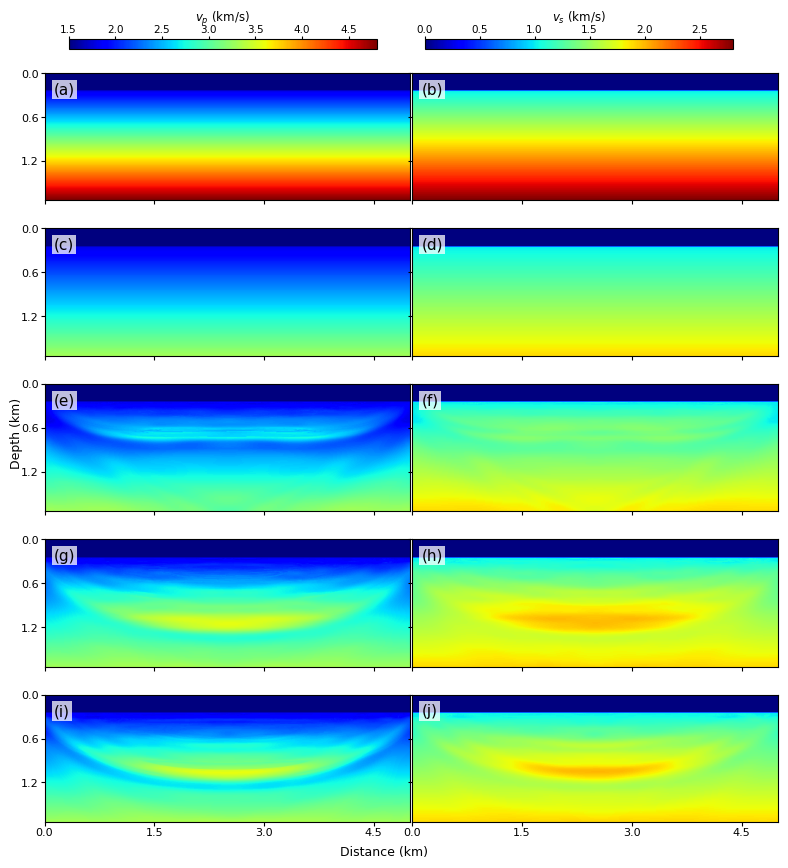

Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear_compact\all_models_5x2_top_cbar.png
Saved: C:\Users\heyuxuan\Desktop\Inversion_results_Linear\save_linear_compact\all_models_5x2_top_cbar.pdf


In [7]:
def crop_model(x, y):
    return x

x_slice = 0

def save_all_models_5x2_top_cbar(
    vp_true, vs_true,
    vp_init, vs_init,
    final_models,
    vp_norm, vs_norm,
    name="all_models_5x2_top_cbar",
    dpi=600,
):
    """
    5 x 2 compact figure:

        row 1: True    -> vp / vs
        row 2: Initial -> vp / vs
        row 3: L2      -> vp / vs
        row 4: COT     -> vp / vs
        row 5: ROT     -> vp / vs

    Two horizontal colorbars are manually placed at the top,
    so they do not consume a whole GridSpec row.
    """
    panels = [
        [crop_model(vp_true, x_slice), crop_model(vs_true, x_slice)],
        [crop_model(vp_init, x_slice), crop_model(vs_init, x_slice)],
        [crop_model(final_models["L2"]["vp"], x_slice),
         crop_model(final_models["L2"]["vs"], x_slice)],
        [crop_model(final_models["COT"]["vp"], x_slice),
         crop_model(final_models["COT"]["vs"], x_slice)],
        [crop_model(final_models["ROT"]["vp"], x_slice),
         crop_model(final_models["ROT"]["vs"], x_slice)],
    ]

    norms = [vp_norm, vs_norm]
    panel_labels = [
        ["(a)", "(b)"],
        ["(c)", "(d)"],
        ["(e)", "(f)"],
        ["(g)", "(h)"],
        ["(i)", "(j)"],
    ]

    # 稍微更宽一些，让每个 panel 更舒展
    fig = plt.figure(figsize=(8.0, 8.9))

    # 这里只给 5x2 的图本身分配空间，不让 colorbar 占格子
    gs = fig.add_gridspec(
        5, 2,
        width_ratios=[1, 1],
        height_ratios=[1, 1, 1, 1, 1],
        wspace=0.005,
        hspace=0.030,
    )

    ims = [None, None]

    for i in range(5):
        for j in range(2):
            ax = fig.add_subplot(gs[i, j])

            im = ax.imshow(
                panels[i][j].T,
                cmap=CMAP,
                norm=norms[j],
                origin="upper",
                extent=get_extent(panels[i][j]),
                aspect="equal",
            )
            ims[j] = im

            add_panel_label(ax, panel_labels[i][j])

            format_model_axis(
                ax,
                show_xlabel=(i == 4),
                show_ylabel=(j == 0),
            )

    # 主体尽量铺满
    # Main panels occupy more of the canvas
    fig.subplots_adjust(
        left=0.075,
        right=0.992,
        bottom=0.050,
        top=0.918,
    )

    # ============================================================
    # Manually placed top colorbars
    # ============================================================
    cax_vp = fig.add_axes([0.105, 0.932, 0.385, 0.011])
    cax_vs = fig.add_axes([0.550, 0.932, 0.385, 0.011])

    cbar_vp = fig.colorbar(
        ims[0],
        cax=cax_vp,
        orientation="horizontal",
    )
    cbar_vp.set_label(r"$v_p$ (km/s)", fontsize=8.5, labelpad=2)
    cbar_vp.ax.tick_params(labelsize=7.5, length=2.5, pad=1.0)
    cbar_vp.ax.xaxis.set_ticks_position("top")
    cbar_vp.ax.xaxis.set_label_position("top")

    cbar_vs = fig.colorbar(
        ims[1],
        cax=cax_vs,
        orientation="horizontal",
    )
    cbar_vs.set_label(r"$v_s$ (km/s)", fontsize=8.5, labelpad=2)
    cbar_vs.ax.tick_params(labelsize=7.5, length=2.5, pad=1.0)
    cbar_vs.ax.xaxis.set_ticks_position("top")
    cbar_vs.ax.xaxis.set_label_position("top")

    # ============================================================
    # Shared axis labels
    # ============================================================
    fig.text(
        0.50, 0.030,
        "Distance (km)",
        ha="center",
        va="center",
        fontsize=9,
    )

    fig.text(
        0.040, 0.50,
        "Depth (km)",
        ha="center",
        va="center",
        rotation="vertical",
        fontsize=9,
    )
    plt.show()
    save_fig(fig, name, dpi=dpi)

save_all_models_5x2_top_cbar(
    vp_true=vp_true,
    vs_true=vs_true,
    vp_init=vp_init,
    vs_init=vs_init,
    final_models=final_models,
    vp_norm=vp_norm,
    vs_norm=vs_norm,
    name="all_models_5x2_top_cbar",
)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# ============================================================
# Basic configuration
# ============================================================
CMAP = "jet"

# 你可以根据自己的模型网格修改
DX = 10.0   # m
DZ = 10.0   # m

# 如果不需要裁剪，保留这个即可
def crop_model(x, y=None):
    return x


def get_extent(model):
    """
    extent for imshow(model.T, origin='upper')
    x in km, z in km
    """
    nx, nz = model.shape
    return [0, (nx - 1) * DX / 1000.0, (nz - 1) * DZ / 1000.0, 0]


def add_panel_label(ax, text):
    ax.text(
        0.015, 0.965, text,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=8,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.2),
    )


def save_fig(fig, name, dpi=600):
    fig.savefig(f"{name}.png", dpi=dpi, bbox_inches="tight")
    fig.savefig(f"{name}.pdf", dpi=dpi, bbox_inches="tight")


def format_model_axis_compact(ax, show_xticklabels=False, show_yticklabels=False):
    """
    紧凑版 model axis：
    - 只保留刻度，不重复写局部 x/y label
    - 是否显示 tick labels 由参数控制
    """
    ax.tick_params(
        axis="both",
        which="major",
        labelsize=7.5,
        length=2.5,
        pad=1.5,
    )

    if not show_xticklabels:
        ax.set_xticklabels([])
    if not show_yticklabels:
        ax.set_yticklabels([])


# ============================================================
# 1. 5x2 inversion results with small titles on each panel
# ============================================================
def save_all_models_5x2_top_cbar(
    vp_true, vs_true,
    vp_init, vs_init,
    final_models,
    vp_norm, vs_norm,
    name="all_models_5x2_top_cbar",
    dpi=600,
    x_slice=0,
):
    """
    5 x 2 compact figure:

        row 1: True    -> vp / vs
        row 2: Initial -> vp / vs
        row 3: L2      -> vp / vs
        row 4: COT     -> vp / vs
        row 5: ROT     -> vp / vs

    Two horizontal colorbars are manually placed at the top.
    Each panel has a small title, e.g. "True: vp", "L2: vs".
    """

    row_names = ["True", "Initial", "L2", "COT", "ROT"]
    col_names = [r"$v_p$", r"$v_s$"]

    panels = [
        [crop_model(vp_true, x_slice), crop_model(vs_true, x_slice)],
        [crop_model(vp_init, x_slice), crop_model(vs_init, x_slice)],
        [crop_model(final_models["L2"]["vp"],  x_slice),
         crop_model(final_models["L2"]["vs"],  x_slice)],
        [crop_model(final_models["COT"]["vp"], x_slice),
         crop_model(final_models["COT"]["vs"], x_slice)],
        [crop_model(final_models["ROT"]["vp"], x_slice),
         crop_model(final_models["ROT"]["vs"], x_slice)],
    ]

    norms = [vp_norm, vs_norm]
    panel_labels = [
        ["(a)", "(b)"],
        ["(c)", "(d)"],
        ["(e)", "(f)"],
        ["(g)", "(h)"],
        ["(i)", "(j)"],
    ]

    fig = plt.figure(figsize=(8.0, 8.25))

    gs = fig.add_gridspec(
        5, 2,
        width_ratios=[1, 1],
        height_ratios=[1, 1, 1, 1, 1],
        wspace=0.028,
        hspace=0.012,
    )

    ims = [None, None]

    for i in range(5):
        for j in range(2):
            ax = fig.add_subplot(gs[i, j])

            im = ax.imshow(
                panels[i][j].T,
                cmap=CMAP,
                norm=norms[j],
                origin="upper",
                extent=get_extent(panels[i][j]),
                aspect="equal",
            )
            ims[j] = im

            add_panel_label(ax, panel_labels[i][j])

            # 小标题：告诉读者这一行/这一列对应什么
            ax.set_title(
                f"{row_names[i]}: {col_names[j]}",
                fontsize=8.0,
                pad=.8,
            )

            format_model_axis_compact(
                ax,
                show_xticklabels=(i == 4),
                show_yticklabels=(j == 0),
            )

    # 整体布局
    fig.subplots_adjust(
        left=0.075,
        right=0.992,
        bottom=0.055,
        top=0.920,
    )

    # ============================================================
    # Top colorbars
    # ============================================================
    cax_vp = fig.add_axes([0.105, 0.932, 0.385, 0.011])
    cax_vs = fig.add_axes([0.550, 0.932, 0.385, 0.011])

    cbar_vp = fig.colorbar(
        ims[0],
        cax=cax_vp,
        orientation="horizontal",
    )
    cbar_vp.set_label(r"$v_p$ (km/s)", fontsize=8.5, labelpad=2)
    cbar_vp.ax.tick_params(labelsize=7.5, length=2.5, pad=1.0)
    cbar_vp.ax.xaxis.set_ticks_position("top")
    cbar_vp.ax.xaxis.set_label_position("top")

    cbar_vs = fig.colorbar(
        ims[1],
        cax=cax_vs,
        orientation="horizontal",
    )
    cbar_vs.set_label(r"$v_s$ (km/s)", fontsize=8.5, labelpad=2)
    cbar_vs.ax.tick_params(labelsize=7.5, length=2.5, pad=1.0)
    cbar_vs.ax.xaxis.set_ticks_position("top")
    cbar_vs.ax.xaxis.set_label_position("top")

    # ============================================================
    # Shared axis labels
    # ============================================================
    fig.text(
        0.50, 0.030,
        "Horizontal distance (km)",
        ha="center",
        va="center",
        fontsize=9,
    )

    fig.text(
        0.040, 0.50,
        "Depth (km)",
        ha="center",
        va="center",
        rotation="vertical",
        fontsize=9,
    )

    plt.show()
    save_fig(fig, name, dpi=dpi)


# ============================================================
# 2. Center profile (1x2), style consistent with current paper
# ============================================================
def save_center_profiles_1x2(
    vp_true, vs_true,
    vp_init, vs_init,
    final_models,
    name="center_profiles_1x2",
    dpi=600,
    x_slice=0,
    center_index=None,
    vp_ylim=None,
    vs_ylim=None,
):
    """
    1 x 2 center profile figure.

    Left : center profile of vp
    Right: center profile of vs

    Curves:
        True / Initial / L2 / COT / ROT

    Style:
        x-axis = depth (km)
        y-axis = velocity (km/s)
    """

    vp_true_c = crop_model(vp_true, x_slice)
    vs_true_c = crop_model(vs_true, x_slice)
    vp_init_c = crop_model(vp_init, x_slice)
    vs_init_c = crop_model(vs_init, x_slice)

    vp_l2  = crop_model(final_models["L2"]["vp"],  x_slice)
    vs_l2  = crop_model(final_models["L2"]["vs"],  x_slice)
    vp_cot = crop_model(final_models["COT"]["vp"], x_slice)
    vs_cot = crop_model(final_models["COT"]["vs"], x_slice)
    vp_rot = crop_model(final_models["ROT"]["vp"], x_slice)
    vs_rot = crop_model(final_models["ROT"]["vs"], x_slice)

    nx, nz = vp_true_c.shape

    if center_index is None:
        center_index = nx // 2

    depth = np.arange(nz) * DZ / 1000.0
    x_center_km = center_index * DX / 1000.0

    fig, axes = plt.subplots(
        1, 2,
        figsize=(8.0, 2.7),
        constrained_layout=True,
    )

    line_cfg = {
        "True":    dict(linestyle="-",  linewidth=1.8),
        "Initial": dict(linestyle="--", linewidth=1.25),
        "L2":      dict(linestyle="-",  linewidth=1.15),
        "COT":     dict(linestyle="-",  linewidth=1.15),
        "ROT":     dict(linestyle="-",  linewidth=1.15),
    }

    # ---------------- vp ----------------
    ax = axes[0]
    ax.plot(depth, vp_true_c[center_index, :], label="True",    **line_cfg["True"])
    ax.plot(depth, vp_init_c[center_index, :], label="Initial", **line_cfg["Initial"])
    ax.plot(depth, vp_l2[center_index, :],     label="L2",      **line_cfg["L2"])
    ax.plot(depth, vp_cot[center_index, :],    label="COT",     **line_cfg["COT"])
    ax.plot(depth, vp_rot[center_index, :],    label="ROT",     **line_cfg["ROT"])

    add_panel_label(ax, "(a)")
    ax.set_xlabel("Depth (km)")
    ax.set_ylabel(r"$v_p$ (km/s)")
    ax.grid(alpha=0.25, linewidth=0.6)

    if vp_ylim is not None:
        ax.set_ylim(*vp_ylim)

    # ---------------- vs ----------------
    ax = axes[1]
    ax.plot(depth, vs_true_c[center_index, :], label="True",    **line_cfg["True"])
    ax.plot(depth, vs_init_c[center_index, :], label="Initial", **line_cfg["Initial"])
    ax.plot(depth, vs_l2[center_index, :],     label="L2",      **line_cfg["L2"])
    ax.plot(depth, vs_cot[center_index, :],    label="COT",     **line_cfg["COT"])
    ax.plot(depth, vs_rot[center_index, :],    label="ROT",     **line_cfg["ROT"])

    add_panel_label(ax, "(b)")
    ax.set_xlabel("Depth (km)")
    ax.set_ylabel(r"$v_s$ (km/s)")
    ax.grid(alpha=0.25, linewidth=0.6)

    if vs_ylim is not None:
        ax.set_ylim(*vs_ylim)

    # shared legend
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="upper center",
        ncol=5,
        frameon=False,
        bbox_to_anchor=(0.5, 1.05),
        fontsize=8,
    )

    plt.show()
    save_fig(fig, name, dpi=dpi)

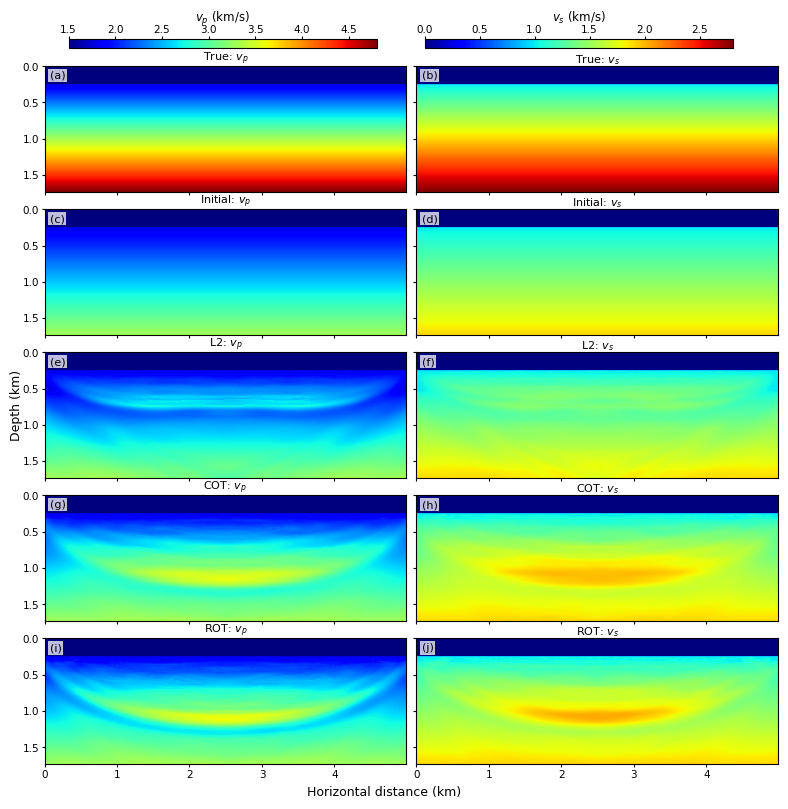

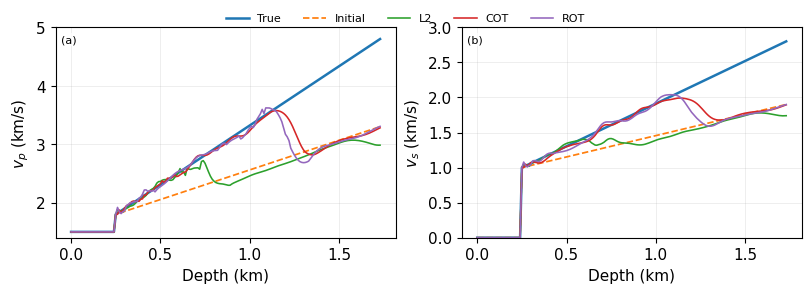

In [3]:
save_all_models_5x2_top_cbar(
    vp_true=vp_true,
    vs_true=vs_true,
    vp_init=vp_init,
    vs_init=vs_init,
    final_models=final_models,
    vp_norm=vp_norm,
    vs_norm=vs_norm,
    name="all_models_5x2_top_cbar_revised_corrected",
)

save_center_profiles_1x2(
    vp_true=vp_true,
    vs_true=vs_true,
    vp_init=vp_init,
    vs_init=vs_init,
    final_models=final_models,
    name="center_profiles_1x2_revised_corrected",
    vp_ylim=(1.4, 5.0),   # 可按需要调
    vs_ylim=(0.0, 3.0),   # 可按需要调
)

In [7]:
def save_center_profiles_true_initial_1x2(
    vp_true, vs_true,
    vp_init, vs_init,
    name="center_profiles_true_initial_1x2",
    dpi=600,
    x_slice=0,
    center_index=None,
    vp_ylim=None,
    vs_ylim=None,
):
    """
    1 x 2 center profile figure.

    Left : center profile of vp
    Right: center profile of vs

    Curves:
        True / Initial

    Style:
        x-axis = depth (km)
        y-axis = velocity (km/s)
    """

    vp_true_c = crop_model(vp_true, x_slice)
    vs_true_c = crop_model(vs_true, x_slice)
    vp_init_c = crop_model(vp_init, x_slice)
    vs_init_c = crop_model(vs_init, x_slice)

    nx, nz = vp_true_c.shape

    if center_index is None:
        center_index = nx // 2

    depth = np.arange(nz) * DZ / 1000.0

    fig, axes = plt.subplots(
        1, 2,
        figsize=(8.0, 2.7),
        constrained_layout=True,
    )

    line_cfg = {
        "True": dict(
            linestyle="-",
            linewidth=1.8,
        ),
        "Initial": dict(
            linestyle="--",
            linewidth=1.25,
        ),
    }

    # ============================================================
    # vp
    # ============================================================
    ax = axes[0]

    ax.plot(
        depth,
        vp_true_c[center_index, :],
        label="True",
        **line_cfg["True"],
    )

    ax.plot(
        depth,
        vp_init_c[center_index, :],
        label="Initial",
        **line_cfg["Initial"],
    )

    add_panel_label(ax, "(a)")

    ax.set_xlabel("Depth (km)")
    ax.set_ylabel(r"$v_p$ (km/s)")
    ax.grid(alpha=0.25, linewidth=0.6)

    if vp_ylim is not None:
        ax.set_ylim(*vp_ylim)

    # ============================================================
    # vs
    # ============================================================
    ax = axes[1]

    ax.plot(
        depth,
        vs_true_c[center_index, :],
        label="True",
        **line_cfg["True"],
    )

    ax.plot(
        depth,
        vs_init_c[center_index, :],
        label="Initial",
        **line_cfg["Initial"],
    )

    add_panel_label(ax, "(b)")

    ax.set_xlabel("Depth (km)")
    ax.set_ylabel(r"$v_s$ (km/s)")
    ax.grid(alpha=0.25, linewidth=0.6)

    if vs_ylim is not None:
        ax.set_ylim(*vs_ylim)

    # ============================================================
    # Shared legend
    # ============================================================
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=2,
        frameon=False,
        bbox_to_anchor=(0.5, 1.05),
        fontsize=8,
    )

    plt.show()

    save_fig(
        fig,
        name,
        dpi=dpi,
    )

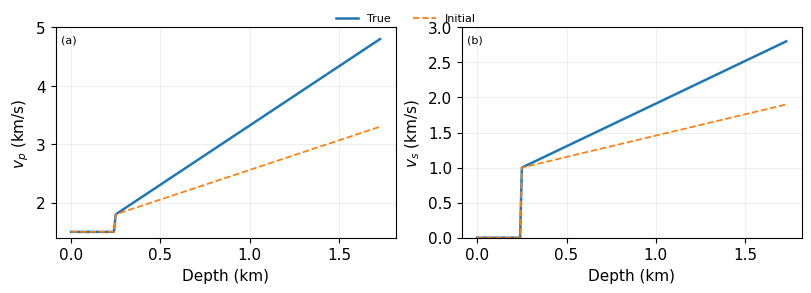

In [8]:
save_center_profiles_true_initial_1x2(
    vp_true=vp_true,
    vs_true=vs_true,
    vp_init=vp_init,
    vs_init=vs_init,
    name="center_profiles_true_initial_1x2",
    vp_ylim=(1.4, 5.0),   # 可按需要调
    vs_ylim=(0.0, 3.0),   # 可按需要调
)